# Lab01
<a id="colorlab-1" name="colorlab-1"></a>

## 1. Статистический анализ яркости и насыщенности изображений

### Как читать исследование

Этот ноутбук — вычислительная основа сайта **COLOR LAB**. Последовательно рассматриваются две случайные величины: средняя яркость HSV V и средняя насыщенность HSV S изображения. Поскольку для конкретной фотографии обе характеристики вычисляются по известным пикселям, **случайность относится к выбору изображения**, а не к самой формуле.

Каждый шаг содержит математическую цель, вычисления и интерпретацию. Веб-версия сохраняет эти результаты и добавляет интерактивные опыты.

**Область применимости:** исследуемая конечная совокупность — **10 000 тестовых изображений CIFAR-10**, а не все фотографии мира. При статистическом моделировании для более широкой популяции нужны дополнительные предположения о репрезентативности.


**Интерактивная часть выполнена в marimo.** Работа опубликована как COLOR LAB на GitHub Pages: [открыть интерактивное приложение](https://kristina344.github.io/ColorLab/). Приложение дополняет вычислительный отчёт и позволяет исследовать фотографии, выборки, распределения и генераторы в браузере.


## Содержание

Выберите раздел — ссылка перенесёт к соответствующей части исследования.

**[1. Статистический анализ яркости и насыщенности изображений](#colorlab-1)**  
**[2. Разведочный анализ данных (EDA)](#colorlab-2)**  
&nbsp;&nbsp;&nbsp;[2.1. Описательная статистика](#colorlab-2-1)  
&nbsp;&nbsp;&nbsp;[2.2. Вывод по описательной статистике](#colorlab-2-2)  
&nbsp;&nbsp;&nbsp;[2.3. Анализ разброса и выбросов](#colorlab-2-3)  
&nbsp;&nbsp;&nbsp;[2.4. Вывод по диаграммам размаха](#colorlab-2-4)  
**[3. Исследование зависимости случайных величин](#colorlab-3)**  
&nbsp;&nbsp;&nbsp;[3.1. Анализ зависимости с помощью диаграммы плотности и корреляции](#colorlab-3-1)  
&nbsp;&nbsp;&nbsp;[3.2. Проверка статистической гипотезы](#colorlab-3-2)  
&nbsp;&nbsp;&nbsp;[3.3. Вывод по проверке гипотезы](#colorlab-3-3)  
**[4. Математическое описание распределений](#colorlab-4)**  
&nbsp;&nbsp;&nbsp;[4.1. Выбор теоретических моделей](#colorlab-4-1)  
&nbsp;&nbsp;&nbsp;[4.2. Предварительный вывод по распределениям](#colorlab-4-2)  
&nbsp;&nbsp;&nbsp;[4.3. Вывод по сравнению моделей](#colorlab-4-3)  
&nbsp;&nbsp;&nbsp;[4.4. Уточнение распределения насыщенности](#colorlab-4-4)  
&nbsp;&nbsp;&nbsp;[4.5. Вывод по бета-модели](#colorlab-4-5)  
**[5. Нормализация и стандартизация данных](#colorlab-5)**  
&nbsp;&nbsp;&nbsp;[5.1. Вывод по стандартизации](#colorlab-5-1)  
**[6. Исследование выборок](#colorlab-6)**  
&nbsp;&nbsp;&nbsp;[6.1. Генеральная совокупность и способы отбора](#colorlab-6-1)  
&nbsp;&nbsp;&nbsp;[6.2. Вывод по сравнению выборок](#colorlab-6-2)  
**[7. Проверка состоятельности оценок](#colorlab-7)**  
&nbsp;&nbsp;&nbsp;[7.1. Идея эксперимента](#colorlab-7-1)  
&nbsp;&nbsp;&nbsp;[7.2. Вывод по состоятельности оценок](#colorlab-7-2)  
**[8. Проверка качества подобранных распределений](#colorlab-8)**  
&nbsp;&nbsp;&nbsp;[8.1. Q–Q графики и критерий Колмогорова — Смирнова](#colorlab-8-1)  
&nbsp;&nbsp;&nbsp;[8.2. Вывод по проверке распределений](#colorlab-8-2)  
**[9. Общий вывод по исследованию](#colorlab-9)**  
**[10. Список использованных источников](#colorlab-10)**  
**[11. cat_mark_table — выполнение критериев](#colorlab-11)**  

Также можно использовать встроенное оглавление Google Colab или Jupyter, чтобы перемещаться между разделами.


### Подготовка данных в Google Colab

Следующая ячейка подготавливает значения средней яркости и насыщенности для **10 000 изображений CIFAR-10**. Данные встроены в ноутбук, поэтому для воспроизведения вычислений не требуется скачивать датасет или подключать GitHub. Запустите **«Среда выполнения → Выполнить все»**, чтобы повторить расчёты.

Для просмотра готового отчёта запускать код не обязательно: ниже сохранены результаты и выводы.

In [26]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/kristina344/ColorLab/main/data/photo_color_data.csv"

df = pd.read_csv(url)
brightness = df["brightness"].to_numpy()
saturation = df["saturation"].to_numpy()

print(f"Загружено изображений: {len(df)}")

Загружено изображений: 10000


<a id="colorlab-2" name="colorlab-2"></a>

## 2. Разведочный анализ данных (EDA)

<a id="colorlab-2-1" name="colorlab-2-1"></a>

### 2.1. Описательная статистика

После преобразования RGB в HSV для каждого изображения были рассчитаны два показателя: средняя яркость и средняя насыщенность.


Средняя яркость изображения:

$$
X = \frac{1}{1024}\sum_{i=1}^{1024}V_i
$$

Средняя насыщенность изображения:

$$
Y = \frac{1}{1024}\sum_{i=1}^{1024}S_i
$$

Здесь $V_i$ и $S_i$ — яркость и насыщенность
отдельного пикселя в модели HSV. Каждое изображение содержит 32 × 32 = 1024 пикселя.


В результате получено 10 000 пар значений. Каждая пара соответствует одному изображению.

Для начала рассмотрим основные статистические характеристики обеих величин: среднее, медиану, минимум, максимум, дисперсию, стандартное отклонение и квартили. Эти показатели помогут понять, какие значения чаще встречаются в данных, насколько сильно они различаются и есть ли заметная асимметрия.

<a id="colorlab-2-1-1" name="colorlab-2-1-1"></a>

### 2.1.1. Обозначения и формулы описательной статистики

Обозначим значения выбранной характеристики на изображениях как $x_1,\ldots,x_n$, где $n=10\,000$. Для каждого изображения яркость и насыщенность предварительно усреднены по $32\cdot32=1024$ пикселям.

Выборочное среднее:

$$
\overline{x}=\frac{1}{n}\sum_{i=1}^{n}x_i.
$$

Выборочная дисперсия с поправкой Бесселя:

$$
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\overline{x})^2.
$$

В Pandas это `df.var()` (по умолчанию `ddof=1`). При рассмотрении всех **10 000 записей как конечной генеральной совокупности** для её дисперсии используется деление на $N$ (`ddof=0`). Эти две величины похожи, но имеют разный смысл; при сравнении выборки с генеральной совокупностью явно указываем, какую дисперсию используем.


In [27]:
import pandas as pd

df = pd.DataFrame({
    "Яркость": brightness,
    "Насыщенность": saturation
})

statistics = df.describe().T

statistics["Дисперсия"] = df.var()

print(statistics.round(4).to_string())

                count    mean     std     min     25%     50%     75%     max  Дисперсия
Яркость       10000.0  0.5427  0.1279  0.0797  0.4606  0.5370  0.6229  0.9899     0.0164
Насыщенность  10000.0  0.2725  0.1403  0.0000  0.1702  0.2539  0.3557  0.9441     0.0197


<a id="colorlab-2-2" name="colorlab-2-2"></a>

### 2.2 Вывод по описательной статистике

Я рассчитала основные статистические характеристики для 10 000 изображений CIFAR-10.

1. Средняя яркость составила 0,5427, а средняя насыщенность 0,2725. Получается, что изображения в среднем имеют умеренную яркость, но насыщенность цветов заметно ниже.

2. Стандартное отклонение насыщенности 0,1403 немного больше, чем у яркости 0,1279. Это говорит о том, что насыщенность сильнее изменяется относительно своего среднего значения в абсолютных единицах шкалы HSV.

3. Также я заметила, что у обеих величин среднее немного больше медианы. Особенно это заметно у насыщенности, поэтому можно предположить, что её распределение имеет правостороннюю асимметрию но еще не факт, поэтому следующим шагом построю гистограммы распределений.

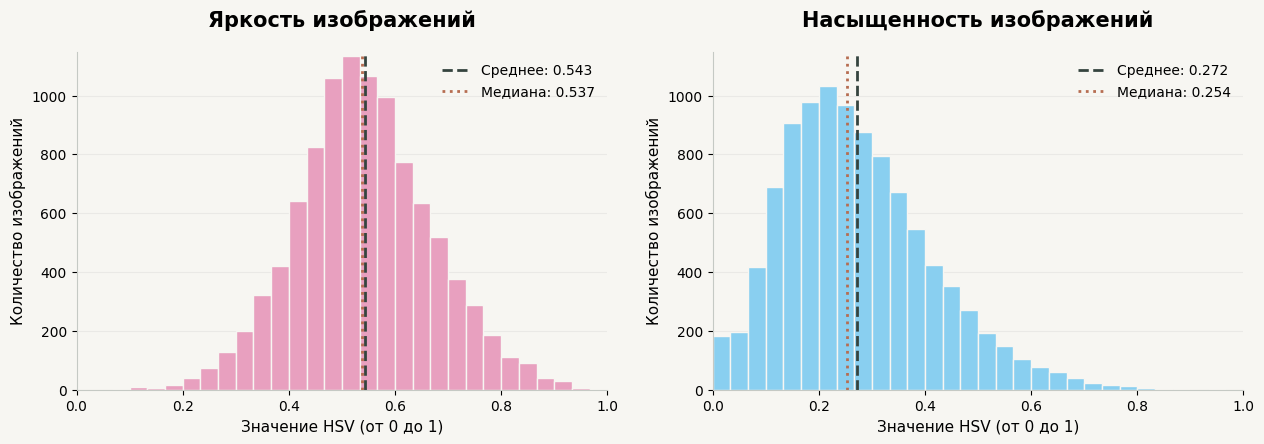

In [28]:
import matplotlib.pyplot as plt
colors = ["#E8A0BF", "#89CFF0"]
background = "#F7F6F2"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
fig.patch.set_facecolor(background)

for ax, values, title, color in zip(
    axes,
    [brightness, saturation],
    ["Яркость изображений", "Насыщенность изображений"],
    colors
):
    ax.set_facecolor(background)

    ax.hist(values, bins=30, range=(0, 1),
            color=color, edgecolor=background, linewidth=1)

    mean = np.mean(values)
    median = np.median(values)

    ax.axvline(mean, color="#35443F", linestyle="--",
               linewidth=2, label=f"Среднее: {mean:.3f}")

    ax.axvline(median, color="#B66D51", linestyle=":",
               linewidth=2, label=f"Медиана: {median:.3f}")

    ax.set_title(title, fontsize=15, fontweight="bold", pad=18)
    ax.set_xlabel("Значение HSV (от 0 до 1)", fontsize=11)
    ax.set_ylabel("Количество изображений", fontsize=11)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1150)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C5C9C4")
    ax.spines["bottom"].set_color("#C5C9C4")

plt.tight_layout(pad=2)
plt.show()

<a id="colorlab-2-3" name="colorlab-2-3"></a>

### 2.3. Анализ разброса и выбросов

Для дополнительного исследования распределений построим диаграммы размаха (boxplot) то бишь ящик с усами, который помогает понять, где сосредоточена основная часть значений и какие наблюдения сильно отличаются от остальных.
Будем использовать правило 1,5 межквартильного размаха.

Межквартильный размах:

$$
IQR = Q_3 - Q_1
$$

Нижняя граница:

$$
L = Q_1 - 1.5 \cdot IQR
$$

Верхняя граница:

$$
U = Q_3 + 1.5 \cdot IQR
$$

Значения за этими границами будем считать потенциальными выбросами. При этом они не обязательно являются ошибками в данных.

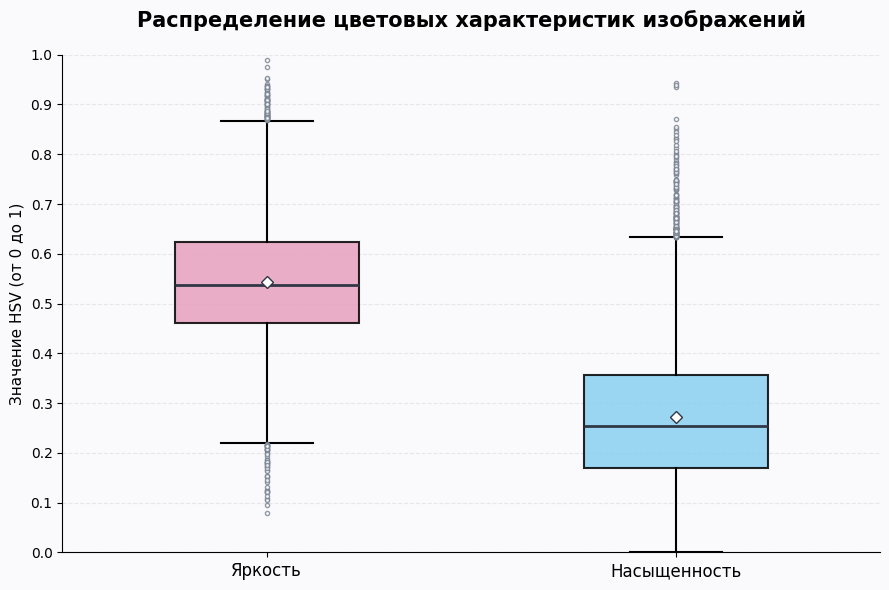

In [29]:
fig, ax = plt.subplots(figsize=(9, 6))
fig.patch.set_facecolor("#FAFAFC")
ax.set_facecolor("#FAFAFC")

bp = ax.boxplot(
    [brightness, saturation],
    positions=[1, 2],
    widths=0.45,
    patch_artist=True,
    showmeans=True,
    boxprops={"linewidth": 1.5},
    medianprops={"color": "#303846", "linewidth": 2},
    meanprops={"marker": "D", "markerfacecolor": "white",
               "markeredgecolor": "#303846", "markersize": 6},
    whiskerprops={"linewidth": 1.5},
    capprops={"linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 3,
                "markerfacecolor": "white",
                "markeredgecolor": "#77818F", "alpha": 0.8}
)

for box, color in zip(bp["boxes"], ["#E8A0BF", "#89CFF0"]):
    box.set_facecolor(color)
    box.set_alpha(0.85)

ax.set_xticks([1, 2])
ax.set_xticklabels(["Яркость", "Насыщенность"], fontsize=12)
ax.set_ylabel("Значение HSV (от 0 до 1)", fontsize=11)
ax.set_title("Распределение цветовых характеристик изображений",
             fontsize=15, fontweight="bold", pad=20)

ax.set_ylim(0, 1)
ax.set_yticks(np.arange(0, 1.01, 0.1))
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

<a id="colorlab-2-4" name="colorlab-2-4"></a>

### 2.4. Вывод по диаграммам размаха

Яркость (розовый): основная половина значений находится примерно между 0,46 и 0,62. Медиана составляет 0,537. Есть потенциальные выбросы как среди очень тёмных, так и среди очень светлых изображений.

Насыщенность (голубой): основная половина значений находится между 0,17 и 0,36. Медиана равна 0,254. Особенно хорошо заметны потенциальные выбросы с высокой насыщенностью. При этом среднее расположено выше медианы, что согласуется с предположением о правосторонней асимметрии.

<a id="colorlab-3" name="colorlab-3"></a>

## 3. Исследование зависимости случайных величин

<a id="colorlab-3-1" name="colorlab-3-1"></a>

### 3.1. Анализ зависимости с помощью диаграммы плотности и корреляции

Обе случайные величины рассчитываются по одним и тем же изображениям, поэтому интересно проверить, существует ли между ними статистическая зависимость.

Для начала построим диаграмму рассеяния. График разделяет значения яркости и насыщенности на шестиугольные области. Чем интенсивнее цвет области, тем больше изображений имеют соответствующее сочетание характеристик.

Затем рассчитаем два коэффициента корреляции:

- **Коэффициент Пирсона** — показывает силу и направление линейной связи.
- **Коэффициент Спирмена** — показывает силу и направление монотонной связи на основе рангов.

Оба коэффициента принимают значения от −1 до 1. Чем ближе модуль коэффициента к 1, тем сильнее соответствующая связь. Значение около нуля указывает на отсутствие выраженной связи данного типа, но не обязательно на независимость величин.

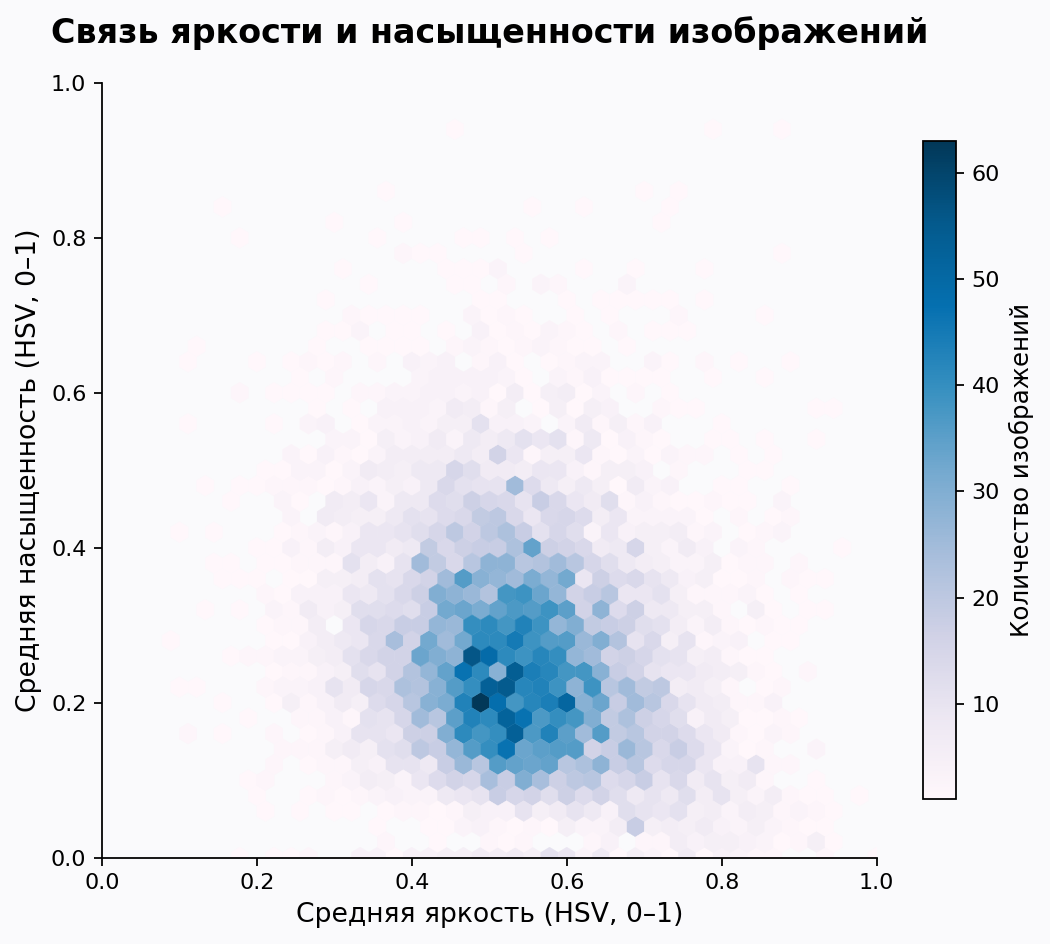

Коэффициент корреляции Пирсона: -0.1889
Коэффициент корреляции Спирмена: -0.1904


In [30]:
from scipy.stats import pearsonr, spearmanr

pearson = pearsonr(brightness, saturation).statistic
spearman = spearmanr(brightness, saturation).statistic

fig, ax = plt.subplots(figsize=(10, 6), dpi=160)

fig.patch.set_facecolor("#FAFAFC")
ax.set_facecolor("#FAFAFC")

hb = ax.hexbin(
    brightness,
    saturation,
    gridsize=45,
    extent=(0, 1, 0, 1),
    cmap="PuBu",
    mincnt=1,
    linewidths=0.2
)

cbar = fig.colorbar(hb, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Количество изображений", fontsize=11)

ax.set_title(
    "Связь яркости и насыщенности изображений",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Средняя яркость (HSV, 0–1)", fontsize=12)
ax.set_ylabel("Средняя насыщенность (HSV, 0–1)", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal", adjustable="box")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Коэффициент корреляции Пирсона: {pearson:.4f}")
print(f"Коэффициент корреляции Спирмена: {spearman:.4f}")

<a id="colorlab-3-2" name="colorlab-3-2"></a>

### 3.2. Проверка статистической гипотезы

По результатам корреляционного анализа была обнаружена слабая отрицательная связь между средней яркостью и насыщенностью изображений.

Теперь проверим, является ли эта связь статистически значимой.

Сформулируем гипотезы:

- **H₀:** средняя яркость и насыщенность изображения независимы.
- **H₁:** между средней яркостью и насыщенностью существует статистическая зависимость.

Для проверки используем перестановочный тест на основе коэффициента корреляции Пирсона. Идея метода заключается в том, что мы случайным образом перемешиваем значения насыщенности, сохраняя значения яркости. Так нарушаются исходные пары наблюдений, но сохраняются отдельные распределения величин. Повторяя перемешивание много раз, можно получить распределение коэффициента корреляции при условии независимости.

Уровень значимости примем равным:

$$
\alpha = 0.05
$$

Если p-value меньше 0,05, отвергаем нулевую гипотезу. Если p-value не меньше 0,05, оснований отвергнуть её недостаточно.

Факт, что выбранный тест использует корреляцию Пирсона как статистику, потому что он хорошо выявляет линейную связь, но не гарантирует обнаружение любой нелинейной зависимости.

<a id="colorlab-3-2-1" name="colorlab-3-2-1"></a>

### 3.2.1. Почему подходит перестановочный тест

**Нулевая гипотеза:** $H_0$ — яркость $X$ и насыщенность $Y$ статистически независимы. При независимости порядок значений $Y$ относительно $X$ не должен содержать систематической информации о соответствии пар.

Обозначим наблюдаемую корреляцию Пирсона $r_{\mathrm{obs}}$. После $B=2000$ случайных перестановок значений $Y$ получаем корреляции $r_1^*,\ldots,r_B^*$ и двустороннюю оценку:

$$
\widehat p=\frac{1+\sum_{b=1}^{B}\mathbf 1\bigl(|r_b^*|\geq |r_{\mathrm{obs}}|\bigr)}{B+1}.
$$

Единица в числителе и знаменателе предотвращает искусственный нулевой результат при конечном числе перестановок. Если $\widehat p<0{,}05$, отвергаем $H_0$ на выбранном уровне значимости. **Важно:** тест на основе корреляции прежде всего обнаруживает линейную связь, поэтому он не является полной проверкой всех возможных нелинейных зависимостей.


In [31]:
rng = np.random.default_rng(42)

n_permutations = 2000
observed_r = np.corrcoef(brightness, saturation)[0, 1]

permuted_r = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled = rng.permutation(saturation)
    permuted_r[i] = np.corrcoef(brightness, shuffled)[0, 1]

p_value = (np.sum(np.abs(permuted_r) >= abs(observed_r)) + 1) / (n_permutations + 1)

print(f"Наблюдаемая корреляция: {observed_r:.4f}")
print(f"Количество перестановок: {n_permutations}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("Нулевая гипотеза отвергается.")
else:
    print("Недостаточно оснований отвергнуть нулевую гипотезу.")

Наблюдаемая корреляция: -0.1889
Количество перестановок: 2000
p-value: 0.000500
Нулевая гипотеза отвергается.


<a id="colorlab-3-3" name="colorlab-3-3"></a>

### 3.3. Вывод по проверке гипотезы

Как я и говорила ранее, для проверки независимости яркости и насыщенности я провела перестановочный тест на основе коэффициента корреляции Пирсона.

Наблюдаемая корреляция составила −0,1889. После 2000 случайных перестановок получилось p-value ≈ 0,0005.

Поскольку полученное значение меньше выбранного уровня значимости 0,05, нулевая гипотеза о независимости отвергается.

Таким образом, в исследуемом наборе изображений обнаружена статистически значимая отрицательная корреляция между яркостью и насыщенностью. При этом сама связь слабая, так как коэффициент корреляции близок к нулю. Это означает, что по одной только яркости нельзя достаточно точно определить насыщенность фотографии. Я также учитываю, что перестановочный тест с коэффициентом Пирсона в первую очередь чувствителен к линейной связи, поэтому его результат не описывает все возможные формы зависимости.

<a id="colorlab-4" name="colorlab-4"></a>

## 4. Математическое описание распределений

<a id="colorlab-4-1" name="colorlab-4-1"></a>

### 4.1. Выбор теоретических моделей

По гистограммам видно, что распределения яркости и насыщенности отличаются.

Кстати распределение яркости напоминает колоколообразную кривую, а у насыщенности заметна правосторонняя асимметрия.

Чтобы не выбирать распределение только по внешнему виду, сравним три теоретические модели: нормальную, бета-распределение и равномерную.

**Нормальное распределение** задаётся плотностью:

$$
f(x)=\frac{1}{\sigma\sqrt{2\pi}}
\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)
$$


**Бета-распределение** имеет плотность:

$$
f(x)=\frac{x^{a-1}(1-x)^{b-1}}{B(a,b)}
$$
Область определения: \(0<x<1\).

**Равномерное распределение** на интервале от 0 до 1 имеет плотность:

$$
f(x)=1,\qquad 0<x<1
$$

Бета-распределение лучше соответствует ограниченной области значений наших величин. Однако наличие точных нулей или единиц требует отдельного рассмотрения, поскольку стандартная бета-модель определена на открытом интервале.

Для сравнения моделей построим гистограммы с теоретическими плотностями и вычислим информационный критерий AIC.

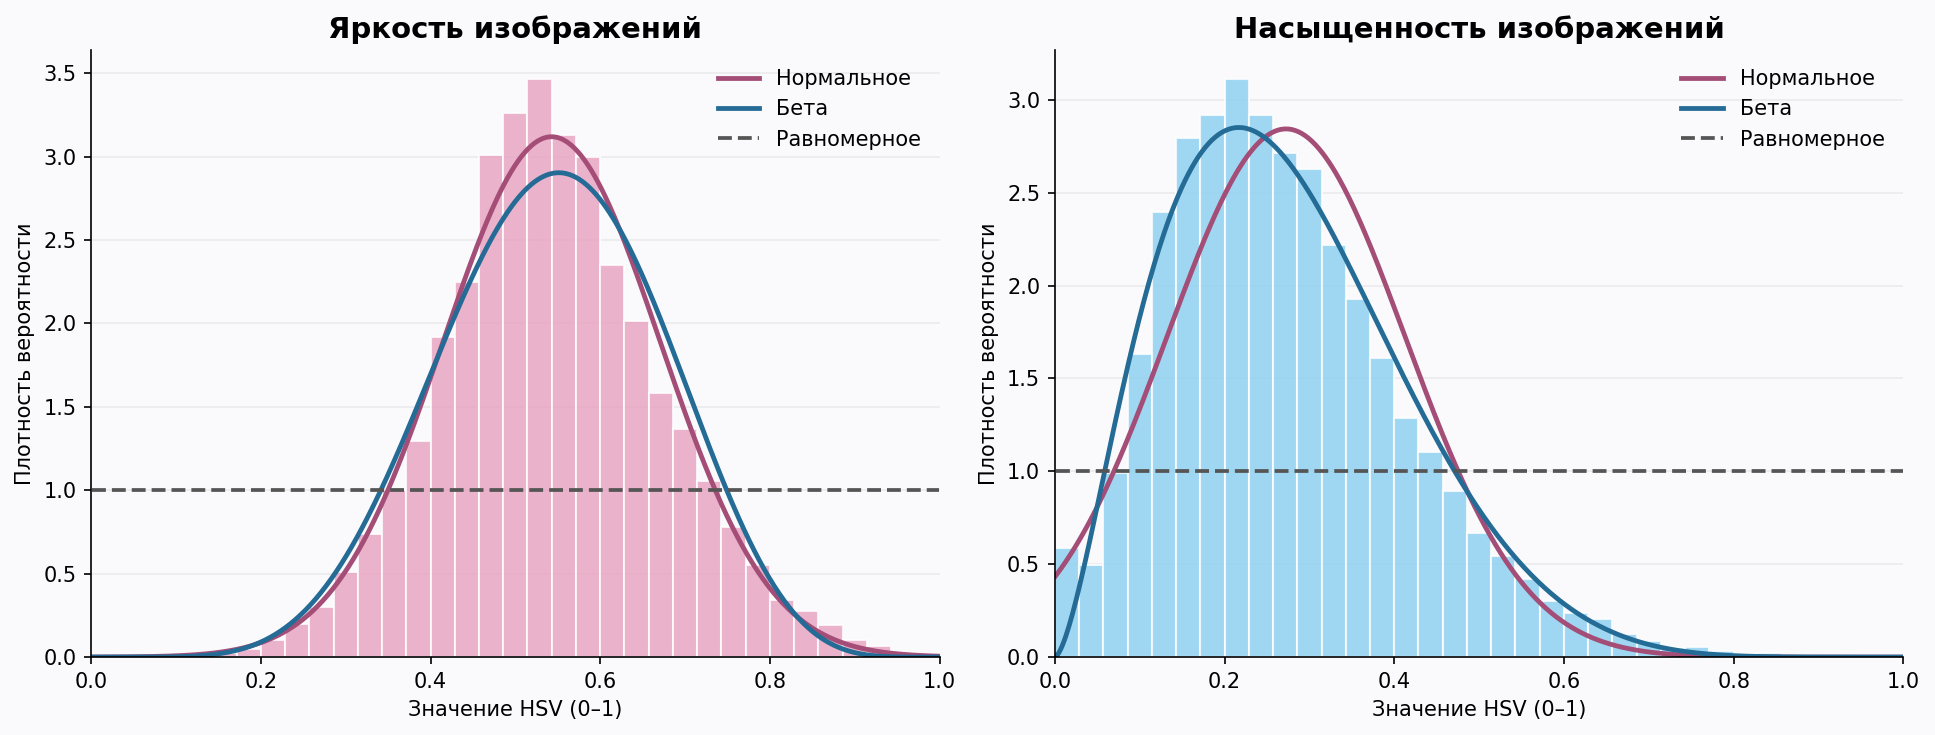

In [32]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
fig.patch.set_facecolor("#FAFAFC")

for ax, values, title, color in zip(
    axes,
    [brightness, saturation],
    ["Яркость изображений", "Насыщенность изображений"],
    ["#E8A0BF", "#89CFF0"]
):
    ax.set_facecolor("#FAFAFC")

    ax.hist(
        values, bins=35, range=(0, 1), density=True,
        color=color, edgecolor="white", alpha=0.8
    )

    mu, sigma = stats.norm.fit(values)
    x = np.linspace(0.001, 0.999, 500)

    a, b, _, _ = stats.beta.fit(
        values[values > 0],
        floc=0, fscale=1
    )

    ax.plot(x, stats.norm.pdf(x, mu, sigma),
            color="#A34D77", linewidth=2.3,
            label="Нормальное")

    ax.plot(x, stats.beta.pdf(x, a, b),
            color="#246B96", linewidth=2.3,
            label="Бета")

    ax.plot(x, stats.uniform.pdf(x, 0, 1),
            color="#555555", linestyle="--",
            linewidth=1.8, label="Равномерное")

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Значение HSV (0–1)")
    ax.set_ylabel("Плотность вероятности")
    ax.set_xlim(0, 1)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

<a id="colorlab-4-2" name="colorlab-4-2"></a>

### 4.2. Предварительный вывод по распределениям

Для яркости нормальное распределение визуально подходит достаточно хорошо, поскольку гистограмма имеет почти симметричную колоколообразную форму. Бета-распределение также близко к данным.

Для насыщенности ситуация другая. Гистограмма имеет заметную правостороннюю асимметрию, поэтому нормальное распределение описывает её хуже. Бета-распределение лучше учитывает форму распределения, хотя тоже не полностью совпадает с гистограммой.

Равномерное распределение не подходит ни для одной из величин, поскольку значения распределены по диапазону неравномерно.

Пока это только визуальное сравнение. Чтобы выбрать более подходящую модель, необходимо дополнительно сравнить численные показатели и проверить качество соответствия распределений данным, что я и сделаю далее.

In [33]:
from scipy import stats

results = []

for name, values in [
    ("Яркость", brightness),
    ("Насыщенность (>0)", saturation[saturation > 0])
]:
    mu, sigma = stats.norm.fit(values)
    normal_aic = 4 - 2 * np.sum(stats.norm.logpdf(values, mu, sigma))

    a, b, _, _ = stats.beta.fit(values, floc=0, fscale=1)
    beta_aic = 4 - 2 * np.sum(stats.beta.logpdf(values, a, b))

    uniform_aic = -2 * np.sum(stats.uniform.logpdf(values, 0, 1))

    results.append([name, "Нормальное", normal_aic])
    results.append([name, "Бета", beta_aic])
    results.append([name, "Равномерное U(0,1)", uniform_aic])

aic_table = pd.DataFrame(
    results,
    columns=["Величина", "Распределение", "AIC"]
)

print(aic_table.round(2).to_string(index=False))
print()
print("Нулевых значений насыщенности:", np.sum(saturation == 0))
print("Доля нулевых значений:", np.mean(saturation == 0))

         Величина      Распределение       AIC
          Яркость         Нормальное -12747.89
          Яркость               Бета -12466.29
          Яркость Равномерное U(0,1)     -0.00
Насыщенность (>0)         Нормальное -11082.03
Насыщенность (>0)               Бета -12116.20
Насыщенность (>0) Равномерное U(0,1)     -0.00

Нулевых значений насыщенности: 106
Доля нулевых значений: 0.0106


<a id="colorlab-4-3" name="colorlab-4-3"></a>

### 4.3. Вывод по сравнению моделей

### 4.3. Вывод по сравнению моделей

Я сравнила нормальное, бета- и равномерное распределения с помощью критерия AIC. Чем меньше значение AIC, тем предпочтительнее модель среди рассмотренных вариантов при сравнении на одинаковых данных.

Для яркости наименьшее значение AIC получилось у нормального распределения −12747,89. Поэтому именно его я выбрала для приближённого описания яркости изображений.

Для положительной насыщенности наименьшее значение AIC получилось у бета-распределения −12116,20. Оно оказалось предпочтительнее нормального и равномерного распределений.

При этом среди 10 000 изображений нашлось 106 с нулевой насыщенностью. Поэтому для полного описания насыщенности я использовала смешанную модель, то есть вероятность нулевого значения составляет 1,06%, а остальные значения описываются бета-распределением.

Полученные модели не являются точным описанием данных, но позволяют достаточно хорошо приблизить их распределения. Дополнительно я проверила их с помощью Q–Q графиков и статистики Колмогорова и Смирнова.

<a id="colorlab-4-4" name="colorlab-4-4"></a>

### 4.4. Уточнение распределения насыщенности
У нас есть 10 000 изображений, из которых:
- 106 имеют нулевую насыщенность.
- 9 894 имеют насыщенность больше нуля.
Мы решили исследовать эти две группы отдельно.

Для 106 изображений мы уже рассчитали вероятность нулевой насыщенности — 1,06%.

Вероятность нулевой насыщенности оценивается как:

$$
\hat p_0=\frac{106}{10000}=0.0106
$$

Для остальных 9 894 изображений мы попробуем подобрать бета-распределение. Его форма зависит от двух параметров \(a\) и \(b\). Рассчитаем их по нашим данным и проверим, насколько хорошо полученная кривая описывает распределение насыщенности.

In [34]:
zero_count = np.sum(saturation == 0)
p_zero = zero_count / len(saturation)

positive_saturation = saturation[saturation > 0]

a, b, _, _ = stats.beta.fit(
    positive_saturation,
    floc=0,
    fscale=1
)

print(f"Количество нулевых значений: {zero_count}")
print(f"Вероятность нулевой насыщенности: {p_zero:.4f}")
print(f"Параметр a: {a:.4f}")
print(f"Параметр b: {b:.4f}")

Количество нулевых значений: 106
Вероятность нулевой насыщенности: 0.0106
Параметр a: 2.6313
Параметр b: 6.8900


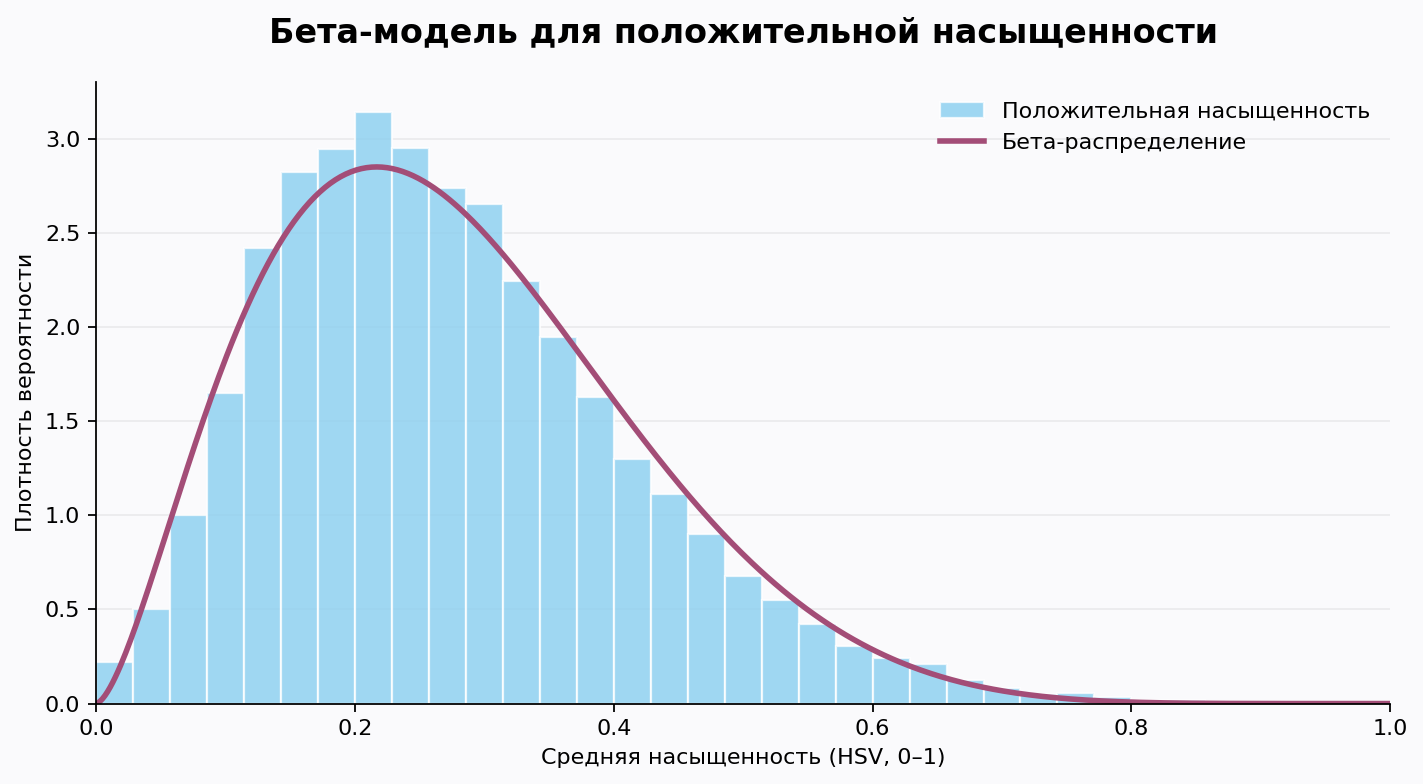

In [35]:
x = np.linspace(0.001, 0.999, 500)

fig, ax = plt.subplots(figsize=(9, 5), dpi=160)
fig.patch.set_facecolor("#FAFAFC")
ax.set_facecolor("#FAFAFC")

ax.hist(
    positive_saturation,
    bins=35,
    range=(0, 1),
    density=True,
    color="#89CFF0",
    edgecolor="white",
    alpha=0.8,
    label="Положительная насыщенность"
)

ax.plot(
    x,
    stats.beta.pdf(x, a, b),
    color="#A34D77",
    linewidth=2.5,
    label="Бета-распределение"
)

ax.set_title(
    "Бета-модель для положительной насыщенности",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Средняя насыщенность (HSV, 0–1)")
ax.set_ylabel("Плотность вероятности")
ax.set_xlim(0, 1)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

<a id="colorlab-4-5" name="colorlab-4-5"></a>

### 4.5. Вывод по бета-модели

Для 9 894 изображений с положительной насыщенностью я подобрала бета-распределение.


В результате я получила следующие параметры бета-распределения:

- Параметр $a = 2.6313$
- Параметр $b = 6.8900$


По графику видно, что полученная кривая достаточно близко повторяет форму гистограммы. Максимум находится примерно в области 0,2–0,3, после чего плотность постепенно уменьшается. При этом кривая не полностью совпадает с данными, особенно в области самых распространённых значений. Поэтому я рассматриваю бета-распределение как приближённую модель, а не как точное описание. Для всех 10 000 изображений отдельно учитывается вероятность нулевой насыщенности — 1,06%. Это позволяет сохранить реальные значения данных и описать распределение намного корректнее.

<a id="colorlab-5" name="colorlab-5"></a>

## 5. Нормализация и стандартизация данных

Яркость и насыщенность уже имеют значения от 0 до 1, поскольку они были рассчитаны в цветовой модели HSV. Поэтому еще приводить их к этому диапазону не требуется.

Однако средние значения и стандартные отклонения двух величин различаются. Чтобы сравнивать отклонения относительно собственных средних значений, я выполню **Z-стандартизацию**.

Для каждого наблюдения из его значения вычитается среднее, а результат делится на стандартное отклонение:

$$
z_i=\frac{x_i-\overline{x}}{s}
$$

После преобразования среднее значение становится близким к нулю, а стандартное отклонение к единице. При этом сами исходные значения яркости и насыщенности сохраняются для дальнейшего анализа.

<a id="colorlab-5-0-1" name="colorlab-5-0-1"></a>

### 5.0.1. Зачем проводить стандартизацию

Исходные $X$ и $Y$ уже нормированы по диапазону $[0,1]$ устройством HSV, но имеют разные средние и стандартные отклонения. Чтобы сравнивать относительное отклонение от среднего в единицах стандартного отклонения, используем:

$$
Z_X=\frac{X-\overline X}{s_X},\qquad Z_Y=\frac{Y-\overline Y}{s_Y}.
$$

Для расчёта $s_X$ и $s_Y$ далее используется `ddof=1`. У стандартизованных значений среднее близко к нулю, а выборочное стандартное отклонение равно единице (с точностью машинных вычислений). **Стандартизация не означает, что распределение стало нормальным.**


In [36]:
brightness_z = (brightness - brightness.mean()) / brightness.std(ddof=1)
saturation_z = (saturation - saturation.mean()) / saturation.std(ddof=1)

comparison = pd.DataFrame({
    "Показатель": ["Яркость", "Насыщенность"],
    "Среднее до": [brightness.mean(), saturation.mean()],
    "Среднее после": [brightness_z.mean(), saturation_z.mean()],
    "Ст. откл. до": [brightness.std(ddof=1), saturation.std(ddof=1)],
    "Ст. откл. после": [brightness_z.std(ddof=1), saturation_z.std(ddof=1)]
})

print(comparison.round(4).to_string(index=False))

  Показатель  Среднее до  Среднее после  Ст. откл. до  Ст. откл. после
     Яркость      0.5427           -0.0        0.1279              1.0
Насыщенность      0.2725            0.0        0.1403              1.0


<a id="colorlab-5-1" name="colorlab-5-1"></a>

### 5.1. Вывод по стандартизации
До преобразования средняя яркость составляла 0,5427, а средняя насыщенность 0,2725. После стандартизации средние значения обеих величин стали практически равны нулю, а стандартные отклонения единице.

Стандартизация выполнена правильно. Теперь можно сравнивать, насколько отдельные изображения отличаются от среднего значения по каждой характеристике. При этом исходные данные я сохранила, поскольку стандартизация изменяет масштаб значений, но не делает распределение нормальным.

<a id="colorlab-6" name="colorlab-6"></a>

## 6. Исследование выборок

<a id="colorlab-6-1" name="colorlab-6-1"></a>

### 6.1. Генеральная совокупность и способы отбора

В качестве конечной генеральной совокупности в этом эксперименте я рассматриваю 10 000 изображений из тестовой части CIFAR-10. Хочу проверить, насколько хорошо случайная выборка меньшего размера отражает характеристики всей совокупности.

Для этого сравню выборки размером 100, 500 и 1000 изображений.

Буду использовать два способа отбора:

- **С возвращением:** после выбора изображение может попасть в выборку повторно.
- **Без возвращения:** каждое изображение может быть выбрано только один раз.

Для каждой выборки рассчитаю среднюю яркость, среднюю насыщенность и их дисперсии, а затем сравню полученные значения с характеристиками всей совокупности.

Поскольку мы знаем характеристики всех 10 000 изображений, сможем непосредственно оценить ошибки выборочных оценок.

<a id="colorlab-6-1-1" name="colorlab-6-1-1"></a>

### 6.1.1. С возвращением и без возвращения

Пусть конечная совокупность состоит из $N=10\,000$ изображений. В выборке объёма $n$:

- **С возвращением:** одно изображение может попасть несколько раз, каждый отбор проводится из всех $N$ изображений.
- **Без возвращения:** каждое изображение может попасть не более одного раза; при $n=N$ выборочное среднее точно совпадает со средним всей конечной совокупности.

При сравнении стандартных ошибок средних для простого случайного отбора без возвращения появляется *поправка на конечность совокупности*:

$$
\operatorname{Var}(\overline X_n)=\frac{S^2}{n}\left(1-\frac{n}{N}\right),
\qquad
S^2=\frac{1}{N-1}\sum_{i=1}^{N}(X_i-\mu_N)^2.
$$

Это объясняет, почему отбор без возвращения обычно даёт меньший разброс среднего. Результат относится к случайному отбору из данной конечной совокупности, а не ко всем фотографиям вообще.


In [37]:
population = np.column_stack((brightness, saturation))

population_mean = population.mean(axis=0)
population_var = population.var(axis=0)

print("Характеристики генеральной совокупности:")
print(f"Средняя яркость: {population_mean[0]:.4f}")
print(f"Средняя насыщенность: {population_mean[1]:.4f}")
print(f"Дисперсия яркости: {population_var[0]:.4f}")
print(f"Дисперсия насыщенности: {population_var[1]:.4f}")

Характеристики генеральной совокупности:
Средняя яркость: 0.5427
Средняя насыщенность: 0.2725
Дисперсия яркости: 0.0164
Дисперсия насыщенности: 0.0197


In [38]:
rng = np.random.default_rng(42)

sample_sizes = [100, 500, 1000]
results = []

for size in sample_sizes:
    for replace, method in [
        (True, "С возвращением"),
        (False, "Без возвращения")
    ]:
        indices = rng.choice(len(population), size=size, replace=replace)
        sample = population[indices]

        means = sample.mean(axis=0)
        variances = sample.var(axis=0, ddof=1)

        results.append([
            size,
            method,
            means[0],
            means[1],
            variances[0],
            variances[1]
        ])

sample_table = pd.DataFrame(
    results,
    columns=[
        "Размер",
        "Способ",
        "Средняя яркость",
        "Средняя насыщенность",
        "Дисперсия яркости",
        "Дисперсия насыщенности"
    ]
)

print(sample_table.round(4).to_string(index=False))

 Размер          Способ  Средняя яркость  Средняя насыщенность  Дисперсия яркости  Дисперсия насыщенности
    100  С возвращением           0.5478                0.2643             0.0218                  0.0143
    100 Без возвращения           0.5136                0.2662             0.0163                  0.0158
    500  С возвращением           0.5601                0.2787             0.0166                  0.0226
    500 Без возвращения           0.5405                0.2806             0.0156                  0.0186
   1000  С возвращением           0.5444                0.2776             0.0142                  0.0215
   1000 Без возвращения           0.5402                0.2747             0.0171                  0.0195


<a id="colorlab-6-2" name="colorlab-6-2"></a>

### 6.2. Вывод по сравнению выборок

В качестве ориентиров взяла характеристики всех 10 000 изображений: среднюю яркость 0,5427 и среднюю насыщенность 0,2725.

По таблице видно, что полученные выборочные средние в целом близки к характеристикам всей совокупности. Особенно небольшие отклонения получились для выборок по 1000 изображений.

Однако я заметила, что при увеличении размера выборки результат не всегда становится точнее. Например, средняя яркость для 500 изображений с возвращением оказалась дальше от среднего, чем для 100 изображений.

Это объясняется случайностью отбора. Поэтому по одному эксперименту нельзя уверенно определить, какой способ лучше и как меняется точность оценок. Чтобы проверить это, дальше я проведу многократный отбор выборок и сравню средние ошибки оценивания.

<a id="colorlab-7" name="colorlab-7"></a>

## 7. Проверка состоятельности оценок

<a id="colorlab-7-1" name="colorlab-7-1"></a>

### 7.1. Идея эксперимента

Состоятельность означает, что при увеличении размера выборки статистическая оценка приближается к оцениваемому параметру. В предыдущем эксперименте я заметила, что одна большая выборка не всегда даёт более точный результат, чем маленькая.

Поэтому теперь для каждого размера выборки проведу 300 случайных повторений. В каждом повторении буду рассчитывать выборочное среднее и дисперсию, а затем сравнивать их с характеристиками всех 10 000 изображений.

Для оценки точности использую среднеквадратичную ошибку (RMSE). Она показывает типичный размер ошибки статистической оценки относительно известного параметра.

$$
RMSE=\sqrt{\frac{1}{m}\sum_{j=1}^{m}(\hat\theta_j-\theta)^2}
$$

Здесь:

- $m$ — количество повторений;
- $\hat\theta_j$ — оценка в одном повторении;
- $\theta$ — характеристика генеральной совокупности.

Чем меньше RMSE, тем точнее оценки в проведённом эксперименте.

Для отбора без возвращения размер выборки не может превышать 10 000. Поэтому вывод о состоятельности в строгом смысле будем связывать с теорией, а графики использовать как эмпирическую демонстрацию уменьшения ошибок.

<a id="colorlab-7-1-1" name="colorlab-7-1-1"></a>

### 7.1.1. Как измеряется точность оценивания

Для каждого размера выборки $n$ и каждого способа отбора выполняются $R=300$ независимых повторений. В каждом повторении $j$ оцениваем среднее и дисперсию; затем сравниваем оценку $\widehat\theta_j$ с характеристикой всей конечной совокупности $\theta_N$:

$$
\operatorname{RMSE}(\widehat\theta)=\sqrt{\frac1R\sum_{j=1}^{R}\left(\widehat\theta_j-\theta_N\right)^2}.
$$

RMSE объединяет разброс оценок и возможное смещение. Если она уменьшается с ростом $n$, результаты поддерживают теоретическую идею состоятельности. **Но одних конечных численных экспериментов недостаточно для строгого доказательства предела при $n\to\infty$.**


In [39]:
rng = np.random.default_rng(42)

sizes = [50, 100, 250, 500, 1000, 2000, 5000]
repeats = 300
results = []

for size in sizes:
    for replace, method in [(True, "С возвращением"), (False, "Без возвращения")]:
        mean_estimates = []
        var_estimates = []

        for _ in range(repeats):
            indices = rng.choice(len(population), size=size, replace=replace)
            sample = population[indices]

            mean_estimates.append(sample.mean(axis=0))
            var_estimates.append(sample.var(axis=0, ddof=1))

        mean_estimates = np.array(mean_estimates)
        var_estimates = np.array(var_estimates)

        mean_rmse = np.sqrt(np.mean((mean_estimates - population_mean) ** 2, axis=0))
        var_rmse = np.sqrt(np.mean((var_estimates - population_var) ** 2, axis=0))

        results.append([
            size, method,
            mean_rmse[0], mean_rmse[1],
            var_rmse[0], var_rmse[1]
        ])

rmse_table = pd.DataFrame(
    results,
    columns=[
        "Размер", "Способ",
        "RMSE среднего яркости",
        "RMSE среднего насыщенности",
        "RMSE дисперсии яркости",
        "RMSE дисперсии насыщенности"
    ]
)

print(rmse_table.round(5).to_string(index=False))

 Размер          Способ  RMSE среднего яркости  RMSE среднего насыщенности  RMSE дисперсии яркости  RMSE дисперсии насыщенности
     50  С возвращением                0.01921                     0.01929                 0.00362                      0.00461
     50 Без возвращения                0.01947                     0.02017                 0.00346                      0.00457
    100  С возвращением                0.01222                     0.01427                 0.00243                      0.00323
    100 Без возвращения                0.01243                     0.01411                 0.00233                      0.00302
    250  С возвращением                0.00810                     0.00877                 0.00152                      0.00203
    250 Без возвращения                0.00766                     0.00847                 0.00144                      0.00209
    500  С возвращением                0.00579                     0.00602                 0.00104      

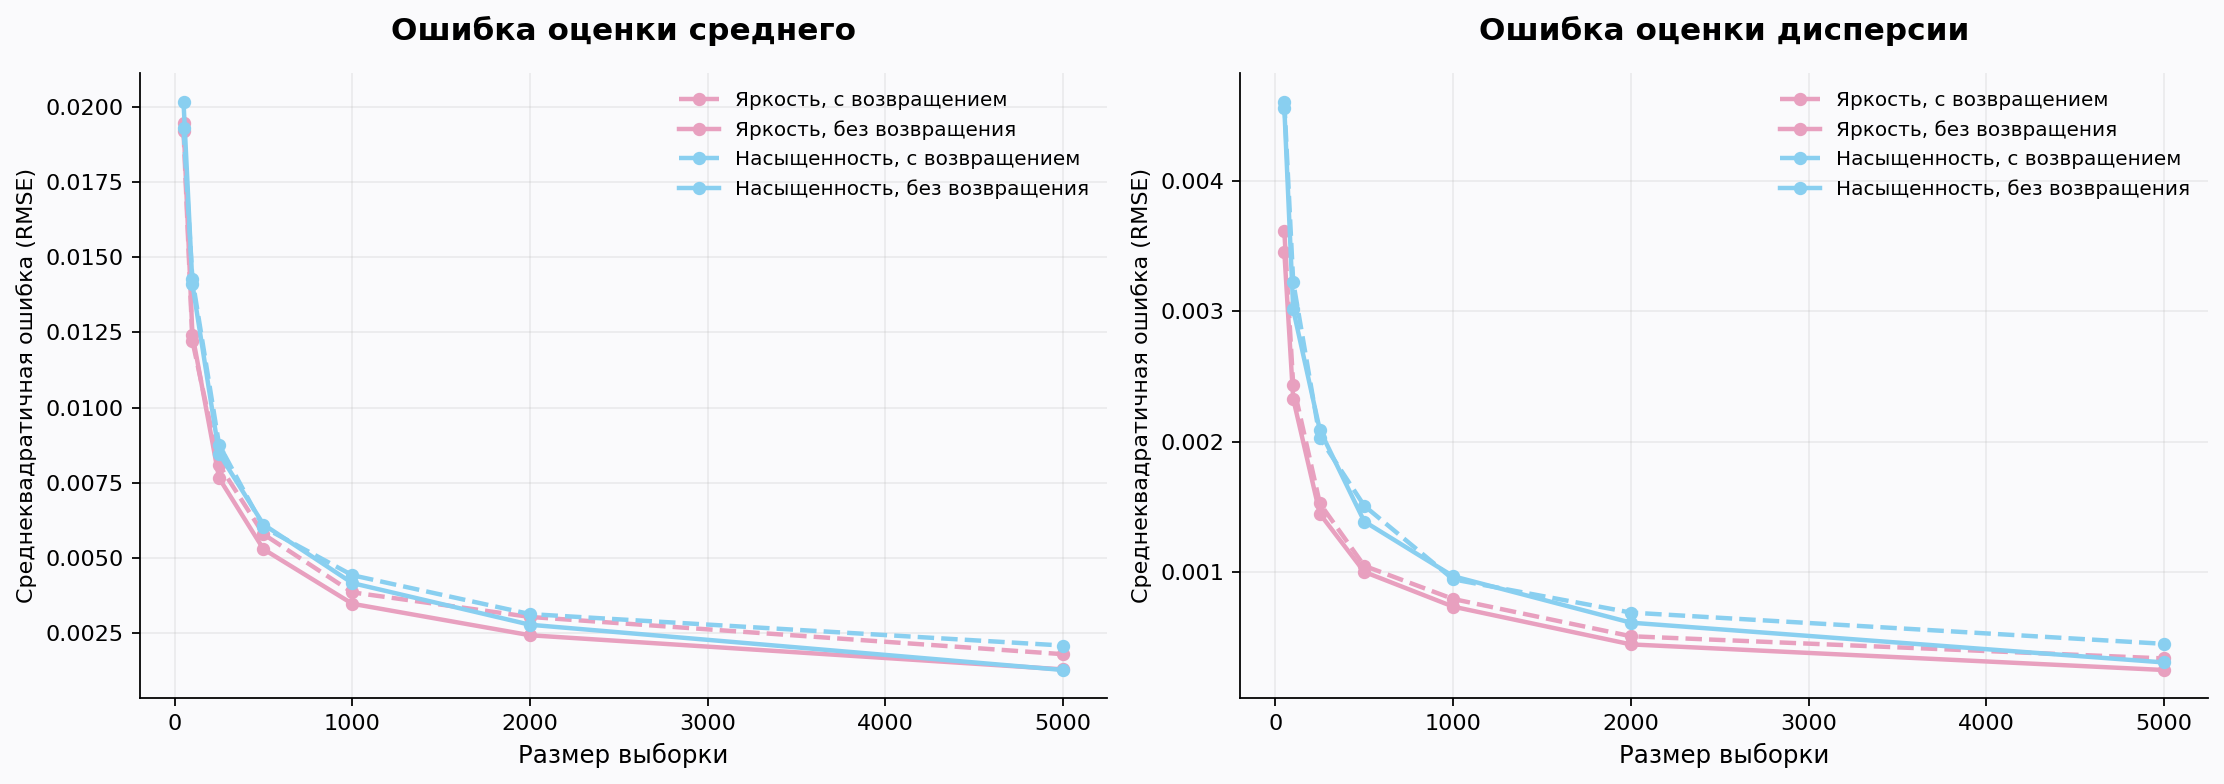

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=160)
fig.patch.set_facecolor("#FAFAFC")

variables = {
    "Яркость": ("яркости", "#E8A0BF"),
    "Насыщенность": ("насыщенности", "#89CFF0")
}

metrics = [
    ("среднего", "Ошибка оценки среднего"),
    ("дисперсии", "Ошибка оценки дисперсии")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.set_facecolor("#FAFAFC")

    for variable, (ending, color) in variables.items():
        for method, linestyle in [
            ("С возвращением", "--"),
            ("Без возвращения", "-")
        ]:
            data = rmse_table[rmse_table["Способ"] == method]

            ax.plot(
                data["Размер"],
                data[f"RMSE {metric} {ending}"],
                color=color,
                linestyle=linestyle,
                marker="o",
                linewidth=2,
                markersize=5,
                label=f"{variable}, {method.lower()}"
            )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Размер выборки", fontsize=11)
    ax.set_ylabel("Среднеквадратичная ошибка (RMSE)", fontsize=10)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

<a id="colorlab-7-2" name="colorlab-7-2"></a>

### 7.2. Вывод по состоятельности оценок

Я провела по 300 случайных экспериментов для каждого размера выборки и сравнила их.

Первый график-ошибка оценки среднего. При увеличении выборки с 50 до 5000 изображений RMSE уменьшается как для яркости, так и для насыщенности. Значит, при большем количестве наблюдений выборочные средние обычно оказываются ближе к средним всей совокупности.

Второй график-ошибка оценки дисперсии. Здесь наблюдаем такую же закономерность. Чем больше изображений берём, тем точнее оцениваем разброс яркости и насыщенности.

Также на больших выборках сплошные линии чаще расположены ниже пунктирных. Это показывает преимущество отбора без возвращения. При небольших выборках разница может быть совсем маленькой.

Таким образом, эксперимент показывает, что увеличение размера выборки повышает точность оценок среднего и дисперсии. Полученные результаты согласуются с теоретическим свойством состоятельности этих оценок.

<a id="colorlab-8" name="colorlab-8"></a>

## 8. Проверка качества подобранных распределений

<a id="colorlab-8-1" name="colorlab-8-1"></a>

### 8.1. Q–Q графики и критерий Колмогорова — Смирнова

Ранее я подобрала нормальное распределение для яркости и смешанную модель для насыщенности. Теперь хочу проверить, насколько хорошо эти модели описывают реальные данные.

Для этого использую два способа.

**Q–Q график** показывает, насколько близки квантили реальных данных к квантилям теоретического распределения. Если точки располагаются примерно вдоль диагонали, значит модель достаточно хорошо описывает данные. Сильные отклонения от диагонали указывают на различия между распределениями.

**Статистика Колмогорова — Смирнова** показывает максимальное расстояние между эмпирической и теоретической функциями распределения.

$$
D = \sup_x |F_n(x)-F(x)|
$$

Здесь:

- $F_n(x)$ — эмпирическая функция распределения;
- $F(x)$ — теоретическая функция распределения;
- $D$ — максимальное расхождение между ними.

Чем меньше значение $D$, тем ближе теоретическая модель к данным по этой характеристике.

Поскольку параметры моделей я оценила по тем же изображениям, обычные значения p-value критерия Колмогорова — Смирнова не будут корректными. Поэтому сначала сравню сами значения статистики и Q–Q графики.

! Для насыщенности отдельно проверю положительные значения, так как 106 изображений имеют насыщенность, равную нулю.

<a id="colorlab-8-1-1" name="colorlab-8-1-1"></a>

### 8.1.1. Ограничения проверки моделей

Для нормальной модели яркости подбираются $\mu$ и $\sigma$, для положительной насыщенности — параметры бета-распределения $\alpha$ и $\beta$. Нулевая насыщенность учитывается отдельно как точечная масса, поскольку стандартная непрерывная бета-плотность сама по себе не описывает атом в нуле.

Q–Q графики помогают увидеть характер отклонений по квантилям. Статистика Колмогорова — Смирнова измеряет максимальное расстояние между эмпирической и теоретической функциями распределения:

$$
D_n=\sup_x\left|F_n(x)-F_\theta(x)\right|.
$$

Поскольку параметры моделей оценены **по этим же данным**, стандартное p-value KS-теста без поправки нельзя автоматически интерпретировать как точное значение уровня значимости. Здесь статистика $D_n$ используется прежде всего как **диагностическая мера расхождения**.


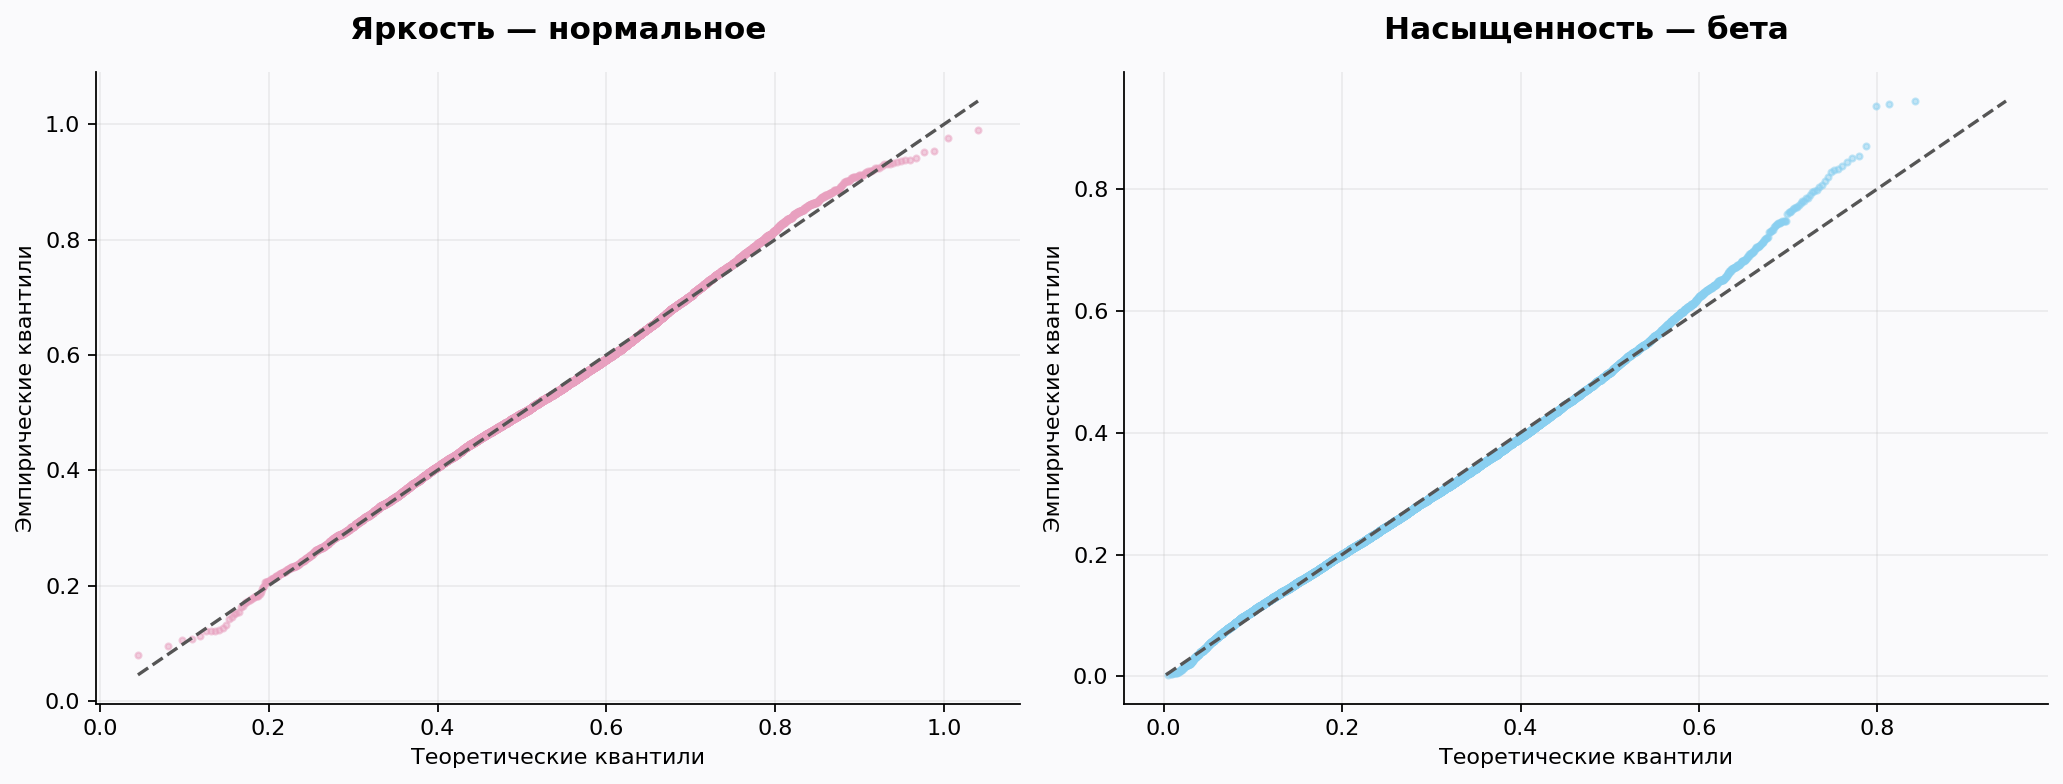

In [41]:
from scipy import stats

mu, sigma = stats.norm.fit(brightness)

probabilities = (np.arange(1, len(brightness) + 1) - 0.5) / len(brightness)
brightness_theory = stats.norm.ppf(probabilities, mu, sigma)

positive_saturation = saturation[saturation > 0]
a, b, _, _ = stats.beta.fit(positive_saturation, floc=0, fscale=1)

probabilities_s = (np.arange(1, len(positive_saturation) + 1) - 0.5) / len(positive_saturation)
saturation_theory = stats.beta.ppf(probabilities_s, a, b)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=160)
fig.patch.set_facecolor("#FAFAFC")

data = [
    (np.sort(brightness), brightness_theory, "#E8A0BF", "Яркость — нормальное"),
    (np.sort(positive_saturation), saturation_theory, "#89CFF0", "Насыщенность — бета")
]

for ax, (observed, theoretical, color, title) in zip(axes, data):
    ax.set_facecolor("#FAFAFC")

    ax.scatter(theoretical, observed, s=7, color=color, alpha=0.5)

    lower = min(observed.min(), theoretical.min())
    upper = max(observed.max(), theoretical.max())

    ax.plot([lower, upper], [lower, upper],
            color="#555555", linestyle="--", linewidth=1.5)

    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Теоретические квантили")
    ax.set_ylabel("Эмпирические квантили")
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [42]:
ks_brightness = stats.kstest(
    brightness,
    "norm",
    args=(mu, sigma)
).statistic

ks_saturation = stats.kstest(
    positive_saturation,
    "beta",
    args=(a, b, 0, 1)
).statistic

ks_table = pd.DataFrame({
    "Величина": ["Яркость", "Положительная насыщенность"],
    "Модель": ["Нормальная", "Бета"],
    "Статистика KS": [ks_brightness, ks_saturation]
})

print(ks_table.round(5).to_string(index=False))
print(f"\nНулевых значений насыщенности: {np.sum(saturation == 0)}")

                  Величина     Модель  Статистика KS
                   Яркость Нормальная        0.02295
Положительная насыщенность       Бета        0.01953

Нулевых значений насыщенности: 106


<a id="colorlab-8-2" name="colorlab-8-2"></a>

### 8.2. Вывод по проверке распределений

Для яркости статистика KS составила 0,02295. На графике большая часть точек находится близко к диагонали, но на краях есть небольшие отклонения. Поэтому нормальное распределение можно использовать как приближённую модель яркости.

Для положительной насыщенности статистика KS составила 0,01953. Бета-распределение тоже достаточно близко описывает данные, но в области высоких значений насыщенности заметны расхождения с теоретической кривой. При этом для насыщенности я отдельно учитываю 106 нулевых значений, которые не входят в стандартную бета-модель.

Таким образом, обе модели подходят для приближённого описания формы данных, но не полностью совпадают с реальными распределениями. По этим результатам нельзя утверждать, что данные точно следуют выбранным теоретическим законам.

<a id="colorlab-9" name="colorlab-9"></a>

## 9. Общий вывод по исследованию

В этой работе я исследовала две характеристики цифровых изображений: среднюю яркость и среднюю насыщенность. Для анализа использовала 10 000 изображений из датасета CIFAR-10. Обе величины рассчитывались по цветовой модели HSV.

Сначала я провела разведочный анализ данных. Средняя яркость изображений составила 0,5427, а средняя насыщенность 0,2725. По гистограммам было видно, что яркость имеет почти симметричное распределение, а насыщенность чаще принимает небольшие значения.

Затем я проверила, существует ли связь между этими характеристиками. Коэффициент корреляции Пирсона составил −0,1889, а Спирмена −0,1904. Оба значения указывают на слабую отрицательную связь. Перестановочный тест дал p-value около 0,0005, поэтому на уровне значимости 0,05 я опровергла гипотезу о независимости величин. Получается, что в исследуемом наборе более яркие изображения имеют небольшую тенденцию быть менее насыщенными, хотя сама связь выражена слабо.

Для описания распределений я рассмотрела несколько математических моделей. Яркость удалось достаточно хорошо приблизить нормальным распределением. Для насыщенности я использовала смешанную модель, поскольку у 106 изображений насыщенность оказалась равна нулю. Для остальных 9 894 изображений было подобрано бета-распределение с параметрами $a = 2.6313$ и $b = 6.8900$.

Проверка с помощью Q–Q графиков и статистики Колмогорова и Смирнова показала, что выбранные модели близко описывают наблюдаемые распределения, хотя полностью с ними не совпадают.

Также я сравнила случайные выборки разного размера. При многократном отборе получилось, что с увеличением количества изображений ошибки оценивания среднего и дисперсии уменьшаются. Это согласуется с теоретическим свойством состоятельности оценок. При больших выборках отбор без возвращения обычно показывал меньшую ошибку.

С точки зрения дизайна исследование показало, что яркость и насыщенность стоит рассматривать как две разные характеристики изображения. Между ними есть статистическая связь, но она недостаточно сильная, чтобы по одной характеристике точно определять другую.

При этом результаты относятся к изображениям CIFAR-10, а не ко всем существующим фотографиям. Кроме того, из-за небольшого разрешения изображений исследование не позволяет оценивать качество профессиональной фотографии или её нишевость и эстетику.

<a id="colorlab-10" name="colorlab-10"></a>

## 10. Список использованных источников

1. Krizhevsky A. *Learning Multiple Layers of Features from Tiny Images*. University of Toronto, 2009.  
   https://cave.cs.toronto.edu/kriz/cifar.html

2. Гмурман В. Е. *Теория вероятностей и математическая статистика*: учебное пособие для вузов.  
   Используется для изучения случайных величин, распределений, выборочных характеристик, статистических оценок и проверки гипотез.

3. Leemis L. M., McQueston J. T. *Univariate Distribution Relationships* // The American Statistician. 2008.

4. SciPy Developers. *SciPy Statistical Functions*. Документация методов статистического анализа, распределений и критериев проверки гипотез.  
   https://docs.scipy.org/doc/scipy/reference/stats.html

5. NumPy Developers. *NumPy Documentation*. Документация библиотеки для численных вычислений.  
   https://numpy.org/doc/stable/

6. Matplotlib Developers. *Matplotlib Documentation*. Документация библиотеки для построения статистических графиков.  
   https://matplotlib.org/stable/


<a id="colorlab-11" name="colorlab-11"></a>

## 11. cat_mark_table — выполнение критериев

| Критерий | Где выполнено | Статус |
|---|---|---|
| Выбор и описание датасета | 1.1 | Выполнено |
| Две случайные величины | 1.2 | Выполнено |
| Обоснование случайной природы | 1.2 | Выполнено |
| Разведочный анализ (EDA) | 2.1–2.4 | Выполнено |
| Исследование зависимости | 3.1 | Выполнено |
| Проверка статистической гипотезы | 3.2–3.3 | Выполнено |
| Математическое описание распределений | 4.1–4.5 | Выполнено |
| Нормализация и стандартизация | 5 | Выполнено |
| Генеральная совокупность и выборки | 6 | Выполнено |
| Состоятельность оценок | 7 | Выполнено |
| Проверка качества моделей | 8 | Выполнено |
| Итоговые выводы | 9 | Выполнено |
| Список источников | 10 | Выполнено |
| Интерактивное приложение marimo | [COLOR LAB - сайт](https://kristina344.github.io/ColorLab/) | Выполнено и опубликовано |


In [43]:
import pandas as pd
import numpy as np

photo_data = pd.DataFrame({
    "image_id": np.arange(len(brightness)),
    "brightness": brightness,
    "saturation": saturation
})

photo_data.to_csv("photo_color_data.csv", index=False)

print("Файл успешно создан!")
print("Количество изображений:", len(photo_data))
print(photo_data.head())

Файл успешно создан!
Количество изображений: 10000
   image_id  brightness  saturation
0         0    0.529626    0.406643
1         1    0.648235    0.202519
2         2    0.568084    0.219500
3         3    0.655587    0.131367
4         4    0.497645    0.294139


In [44]:
# экспорт фотографий для сайта.
if "images" not in globals():
    print("Архив изображений не пересоздаётся: исходные RGB-изображения не входят в этот вычислительный ноутбук.")
    print("Готовый архив для сайта хранится отдельно в репозитории COLOR LAB.")
else:
    from PIL import Image
    from io import BytesIO
    from zipfile import ZipFile
    from google.colab import files

    rng = np.random.default_rng(42)
    selected_ids = np.sort(rng.choice(len(images), size=200, replace=False))

    with ZipFile("cifar10_photos.zip", "w") as archive:
        for image_id in selected_ids:
            buffer = BytesIO()
            Image.fromarray(images[image_id]).save(buffer, format="PNG")
            archive.writestr(f"photos/{image_id:05d}.png", buffer.getvalue())

    print("Сохранено фотографий:", len(selected_ids))

    files.download("cifar10_photos.zip")

Архив изображений не пересоздаётся: исходные RGB-изображения не входят в этот вычислительный ноутбук.
Готовый архив для сайта хранится отдельно в репозитории COLOR LAB.
